# 01 · Burn severity of the Viña del Mar fire (2–3 February 2024)

Reproduces the severity map from scratch: downloads two Sentinel-2 L2A scenes (no account needed), computes dNBR with an unburned-ring offset, classifies with Key and Benson (2006) and **checks that the result is bit-identical to the published one** through a content hash.

- Pre-fire: `S2B_19HBD_20240118_0_L2A` · Post-fire: `S2A_19HBD_20240212_0_L2A` (lowest cloud cover inside the study area in each window, rule fixed before looking at results).
- Study area: Valparaíso, Viña del Mar, Quilpué and Villa Alemana.
- Download size: about 210 MB.

In [1]:
import json, logging, os
from pathlib import Path
logging.basicConfig(level=logging.WARNING, format="%(message)s")
from severidad import calculo, estudio, fuente   # installed with `pip install -e .`

RAW = Path(os.environ.get("INCENDIO_DATOS", "../datos_crudos")).resolve()
PUBLISHED = json.loads(Path("../datos/huellas.json").read_text())
BBOX = estudio.BBOX                              # west, south, east, north
PRE, POST = estudio.PRE_SCENE, estudio.POST_SCENE

## 1. Download (skipped for bands already present) and verify each band

In [2]:
scenes = {s: fuente.download_scene(s, RAW) for s in (PRE, POST)}
for s, bands in scenes.items():
    for b, p in bands.items():
        ok = fuente.sha256(p) == PUBLISHED["scenes"][s][b]
        print(f"{s} {b:7s} {'OK' if ok else 'DIFFERENT FILE'}")

S2B_19HBD_20240118_0_L2A nir08   OK


S2B_19HBD_20240118_0_L2A swir22  OK
S2B_19HBD_20240118_0_L2A scl     OK


S2A_19HBD_20240212_0_L2A nir08   OK


S2A_19HBD_20240212_0_L2A swir22  OK
S2A_19HBD_20240212_0_L2A scl     OK


## 2. Severity

The reflectance offset is **measured on water pixels**: the Earth Search COGs of this collection do not carry the +1000 digital-number offset that their STAC metadata (`raster:bands`) declares, and applying it doubles the burned area (see README, limitation O4).

In [3]:
result = calculo.severity(scenes[PRE], scenes[POST], BBOX)
print(f"water median DN (pre/post): {result.water_dn}; dNBR offset {result.offset:.4f} over {result.ring_pixels} ring pixels")

water median DN (pre/post): (83.0, 29.0); dNBR offset -0.0054 over 350264 ring pixels


## 3. Reproducibility check

In [4]:
out = RAW / "resultado"
out.mkdir(exist_ok=True)
path = out / "clases.tif"
if path.exists():
    path.unlink()
calculo.write_classes(result, path)
h = calculo.content_hash(path)
print(h)
print("IDENTICAL to the published result" if h == PUBLISHED["classes_content_sha256"] else "DIFFERENT from the published result")

ef09b76717fc2855e0fcaf1cd939ecf2e69e6ea7ea416c9f4618e050244f6902
IDENTICAL to the published result


## 4. Area by municipality (boundaries from the public MOP service, SERVICIO_DPA)

In [5]:
from pyproj import Transformer
from shapely.geometry import shape
from shapely.ops import transform

CUT = {"05101": "Valparaíso", "05109": "Viña del Mar", "05801": "Quilpué", "05804": "Villa Alemana"}
local = RAW / "comunas.geojson"
if not local.exists():
    local.write_text(json.dumps(fuente.municipalities(CUT)), encoding="utf-8")
features = json.loads(local.read_text(encoding="utf-8"))["features"]
to_utm = Transformer.from_crs("EPSG:4326", result.crs, always_xy=True)
zones = {CUT[f["properties"]["CUT_COM"]]: transform(to_utm.transform, shape(f["geometry"])) for f in features}
table = calculo.areas(result, zones)
names = {code: name for code, name, *_ in calculo.CLASSES}
print(f"{'':15s}" + "".join(f"{names[c][:16]:>18s}" for c in (4, 5, 6, 7)) + f"{'>= moderate-low':>18s}{'all burned':>14s}")
for z, row in table.items():
    print(f"{z:15s}" + "".join(f"{row[c]:18,.1f}" for c in (4, 5, 6, 7)) + f"{sum(row[c] for c in (5,6,7)):18,.1f}{sum(row[c] for c in (4,5,6,7)):14,.1f}")
print(f"{'Total':15s}" + " " * 72 + f"{sum(sum(r[c] for c in (5,6,7)) for r in table.values()):18,.1f}{sum(sum(r[c] for c in (4,5,6,7)) for r in table.values()):14,.1f}")

                     Low severity  Moderate-low sev  Moderate-high se     High severity   >= moderate-low    all burned
Valparaíso                1,656.2           1,154.4             798.0             330.8           2,283.2       3,939.4
Viña del Mar                865.7             815.9             990.4             589.1           2,395.4       3,261.1
Quilpué                     651.0             556.1             595.6             371.0           1,522.6       2,173.6
Villa Alemana               730.4             361.5             140.0              57.0             558.4       1,288.9
Total                                                                                             6,759.7      10,663.0


**Headline figure: about 6,760 ha at moderate-low severity or higher, within a range up to 10,663 ha if the low-severity class is included.** The threshold was chosen by a rule fixed before validation (higher area-weighted accuracy against Copernicus EMSR715); see notebook 02.

## 5. Map

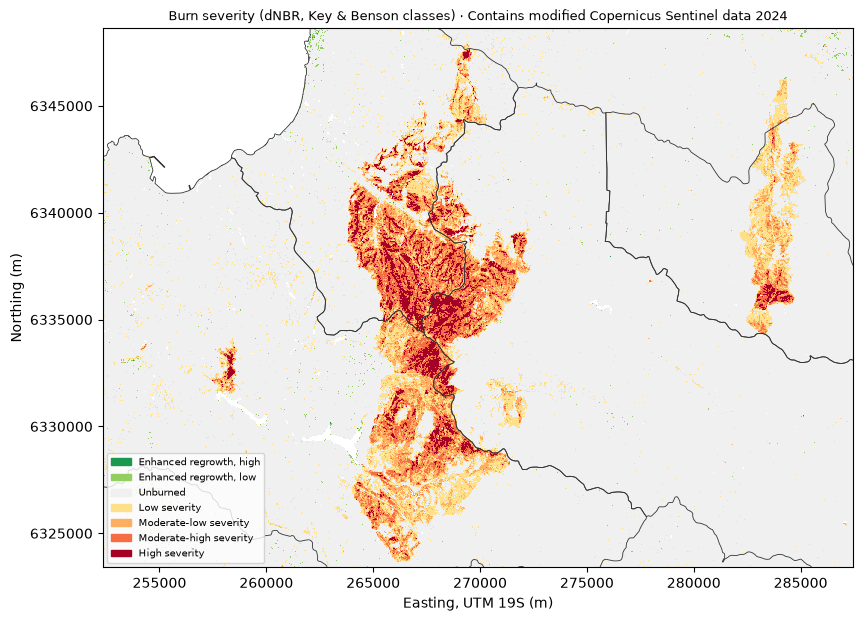

In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
colors = ["#00000000", "#1a9850", "#91cf60", "#f0f0f0", "#fee08b", "#fdae61", "#f46d43", "#a50026"]
cmap, norm = ListedColormap(colors), BoundaryNorm(range(9), 8)
fig, ax = plt.subplots(figsize=(10, 7))
b = result.transform
ext = (b.c, b.c + b.a * result.classes.shape[1], b.f + b.e * result.classes.shape[0], b.f)
ax.imshow(result.classes, cmap=cmap, norm=norm, extent=ext, interpolation="nearest")
for z, g in zones.items():
    for poly in getattr(g, "geoms", [g]):
        ax.plot(*poly.exterior.xy, color="#333", lw=0.6)
ax.set_title("Burn severity (dNBR, Key & Benson classes) · Contains modified Copernicus Sentinel data 2024", fontsize=9)
ax.set_xlabel("Easting, UTM 19S (m)"); ax.set_ylabel("Northing (m)")
ax.ticklabel_format(style="plain", useOffset=False)
ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
handles = [plt.Rectangle((0, 0), 1, 1, color=colors[c]) for c, *_ in calculo.CLASSES]
ax.legend(handles, [n for _, n, *_ in calculo.CLASSES], loc="lower left", fontsize=7)
plt.show()